# Тематические профили альбомов группы «Мельница»

Проект посвящён тематическому моделированию песен группы «Мельница» на материале 9 альбомов 2003–2023 годов.

Главный вопрос исследования: обладают ли альбомы собственными тематическими профилями и связана ли тематическая близость альбомов с хронологией их выхода?

В работе используются автоматический сбор данных, предобработка песенных текстов, TF-IDF, NMF-тематическое моделирование, анализ тематической близости, permutation test и визуализация результатов.

## Предобработка корпуса песен группы «Мельница»

На этом этапе мы загружаем данные, собранные автоматическим скриптом, очищаем тексты песен от технической разметки, создаём две версии корпуса и лемматизируем тексты.

Для песенных текстов особенно важно учитывать повторы: припевы могут искусственно усиливать отдельные слова и темы. Поэтому дальше используются две версии каждого текста:

1. **полный текст** — с сохранением повторов строк;
2. **текст без повторяющихся строк** — чтобы уменьшить влияние припевов.

Обе версии корпуса сохраняются, чтобы позже сравнить результаты тематического моделирования.

In [42]:
import re
import sqlite3
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from tqdm import tqdm

import nltk
from nltk.corpus import stopwords

from pymorphy3 import MorphAnalyzer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram

In [4]:
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\р\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

В базе данных хранятся сведения об альбомах и песнях: название альбома, год выхода, название песни, номер трека, ссылка и путь к файлу с текстом. Загружаем метаданные песен и альбомов в один датафрейм.

In [3]:
connection = sqlite3.connect("melnitsa.db")

songs = pd.read_sql_query("""
    SELECT 
        songs.id AS song_id,
        songs.title AS song_title,
        songs.track_number,
        songs.url AS song_url,
        songs.lyrics_path,
        albums.id AS album_id,
        albums.title AS album_title,
        albums.year AS album_year,
        albums.url AS album_url
    FROM songs
    JOIN albums ON songs.album_id = albums.id
    ORDER BY albums.year, songs.track_number
""", connection)

connection.close()

songs.head()

,song_id,song_title,track_number,song_url,lyrics_path,album_id,album_title,album_year,album_url
0,91,Дорога сна,1,https://genius.com/Melnitsa-the-road-of-dream-...,lyrics\2003_Дорога сна\01_Дорога_сна.txt,9,Дорога сна,2003,https://genius.com/albums/Melnitsa/Dream-road
1,92,Горец,2,https://genius.com/Melnitsa-highlander-lyrics,lyrics\2003_Дорога сна\02_Горец.txt,9,Дорога сна,2003,https://genius.com/albums/Melnitsa/Dream-road
2,93,Ольга,3,https://genius.com/Melnitsa-olga-lyrics,lyrics\2003_Дорога сна\03_Ольга.txt,9,Дорога сна,2003,https://genius.com/albums/Melnitsa/Dream-road
3,94,Лорд Грегори,4,https://genius.com/Melnitsa-lord-gregory-lyrics,lyrics\2003_Дорога сна\04_Лорд_Грегори.txt,9,Дорога сна,2003,https://genius.com/albums/Melnitsa/Dream-road
4,95,Змей,5,https://genius.com/Melnitsa-serpent-lyrics,lyrics\2003_Дорога сна\05_Змей.txt,9,Дорога сна,2003,https://genius.com/albums/Melnitsa/Dream-road


In [6]:
print("Количество песен:", songs["song_id"].nunique())
print("Количество альбомов:", songs["album_id"].nunique())

Количество песен: 100
Количество альбомов: 9


In [4]:
album_overview = (
    songs
    .groupby(["album_year", "album_title"])
    .agg(n_songs=("song_id", "count"))
    .reset_index()
)

album_overview

,album_year,album_title,n_songs
0,2003,Дорога сна,10
1,2005,Перевал,9
2,2006,Зов Крови,14
3,2009,Дикие травы,12
4,2012,Ангелофрения,11
5,2015,Алхимия,12
6,2016,Химера,11
7,2021,Манускрипт,10
8,2023,Символ солнца,11


In [5]:
# Читаем сырые тексты из файлов
songs["lyrics_raw"] = songs["lyrics_path"].apply(
    lambda path: Path(path).read_text(encoding="utf-8")
)

# Убираем строки-разметку
def clean_section_labels(text):
    lines = []

    for line in text.split("\n"):
        line = line.strip()

        if not line:
            continue

        if line.startswith("[") and line.endswith("]"):
            continue

        lines.append(line)

    return "\n".join(lines)


songs["lyrics_clean"] = songs["lyrics_raw"].apply(clean_section_labels)

songs[["album_year", "album_title", "song_title", "lyrics_clean"]].head()

,album_year,album_title,song_title,lyrics_clean
0,2003,Дорога сна,Дорога сна,"Налей еще вина, мой венценосный брат\nСмотри —..."
1,2003,Дорога сна,Горец,"Мой горец — парень удалой\nШирокоплеч, высок, ..."
2,2003,Дорога сна,Ольга,"«Эльга, Эльга!» — звучало над полями\nГде лома..."
3,2003,Дорога сна,Лорд Грегори,Полночный час угрюм и тих\nЛишь гром гремит по...
4,2003,Дорога сна,Змей,"Ах, иначе в былые года\nКолдовала земля с небе..."


In [6]:
# Если строка уже встречалась раньше в этой песне, второй раз её не добавляем
def remove_repeated_lines(text):
    seen = set()
    lines = []

    for line in text.split("\n"):
        line = line.strip()

        if line not in seen:
            seen.add(line)
            lines.append(line)

    return "\n".join(lines)


# Создаём отдельную колонку с текстами без повторяющихся строк
songs["lyrics_no_repeats"] = songs["lyrics_clean"].apply(remove_repeated_lines)


# Считаем, сколько строк было в тексте до и после удаления повторов
songs["n_lines_clean"] = songs["lyrics_clean"].apply(lambda text: len(text.split("\n")))
songs["n_lines_no_repeats"] = songs["lyrics_no_repeats"].apply(lambda text: len(text.split("\n")))
songs["removed_lines"] = songs["n_lines_clean"] - songs["n_lines_no_repeats"]

songs[[
    "album_year",
    "album_title",
    "song_title",
    "n_lines_clean",
    "n_lines_no_repeats",
    "removed_lines"
]].head(20)

,album_year,album_title,song_title,n_lines_clean,n_lines_no_repeats,removed_lines
0,2003,Дорога сна,Дорога сна,32,32,0
1,2003,Дорога сна,Горец,24,19,5
2,2003,Дорога сна,Ольга,28,28,0
3,2003,Дорога сна,Лорд Грегори,24,24,0
4,2003,Дорога сна,Змей,36,36,0
5,2003,Дорога сна,Зима,18,18,0
6,2003,Дорога сна,Оборотень,36,34,2
7,2003,Дорога сна,Воин вереска,38,30,8
8,2003,Дорога сна,Мора,69,31,38
9,2003,Дорога сна,На Север,24,24,0


### Проверка повторов по альбомам

После удаления повторяющихся строк посмотрим, насколько сильно эта операция изменила тексты в разных альбомах.

Для каждого альбома посчитаем:
- среднее количество строк в песне до удаления повторов;
- среднее количество строк после удаления повторов;
- среднее количество удалённых строк.

Это нужно, чтобы понять, насколько выражены повторы припевов и рефренов в разных частях корпуса.

In [7]:
# Считаем средние показатели по альбомам
repeat_stats_by_album = (
    songs
    .groupby(["album_year", "album_title"])
    .agg(
        songs_count=("song_id", "count"),
        mean_lines_before=("n_lines_clean", "mean"),
        mean_lines_after=("n_lines_no_repeats", "mean"),
        mean_removed_lines=("removed_lines", "mean")
    )
    .reset_index()
)

repeat_stats_by_album[
    ["mean_lines_before", "mean_lines_after", "mean_removed_lines"]
] = repeat_stats_by_album[
    ["mean_lines_before", "mean_lines_after", "mean_removed_lines"]
].round(2)

repeat_stats_by_album

,album_year,album_title,songs_count,mean_lines_before,mean_lines_after,mean_removed_lines
0,2003,Дорога сна,10,32.90,27.60,5.30
1,2005,Перевал,9,35.67,33.22,2.44
2,2006,Зов Крови,14,39.79,28.14,11.64
3,2009,Дикие травы,12,38.92,31.33,7.58
4,2012,Ангелофрения,11,37.91,30.09,7.82
5,2015,Алхимия,12,31.50,27.58,3.92
6,2016,Химера,11,34.36,28.27,6.09
7,2021,Манускрипт,10,30.60,28.40,2.20
8,2023,Символ солнца,11,41.64,32.36,9.27


Таблица показывает, что удаление повторяющихся строк заметно влияет на корпус, но не одинаково для всех альбомов. В среднем сильнее всего сокращаются тексты альбомов **«Зов Крови»** и **«Символ солнца»**: в них удаляется около 11,6 и 9,3 строки на песню соответственно. Это может говорить о более выраженной роли припевов, рефренов или повторяющихся строф.

Меньше всего удаление повторов влияет на альбомы **«Манускрипт»** и **«Перевал»**, где среднее число удалённых строк невелико. Поэтому сохранение отдельной версии корпуса без повторов оправдано: она позволяет снизить влияние песенной структуры на дальнейшее тематическое моделирование.

### Лемматизация

Теперь приведём тексты к спискам лемм. Лемматизацию сделаем для двух вариантов корпуса. Дальше основной анализ будет строиться на версии без повторов, но версия с повторами сохранится для сравнения.

In [8]:
morph = MorphAnalyzer()

stop_words = set(stopwords.words("russian"))

extra_stop_words = {
    "это", "этот", "тот", "весь", "всё", "все", "свой", "мой", "твой", "наш", "ваш",
    "быть", "стать", "мочь", "хотеть", "знать", "сказать", "говорить",
    "видеть", "смотреть", "идти", "пойти", "прийти", "уйти", "жить",
    "ещё", "уже", "лишь", "только", "снова", "опять", "будто", "словно",
    "точно", "просто", "вот", "там", "тут", "здесь", "туда", "сюда",
    "ах", "ох", "эй", "ой"
}

stop_words = stop_words | extra_stop_words


def lemmatize_text(text):
    lemmas = []
    words = re.findall(r"[а-яё]+", text.lower())

    for word in words:
        if len(word) < 3:
            continue

        lemma = morph.parse(word)[0].normal_form

        if lemma not in stop_words:
            lemmas.append(lemma)

    return lemmas


songs["lemmas_with_repeats"] = songs["lyrics_clean"].apply(lemmatize_text)
songs["lemmas_no_repeats"] = songs["lyrics_no_repeats"].apply(lemmatize_text)

songs["n_lemmas_with_repeats"] = songs["lemmas_with_repeats"].apply(len)
songs["n_lemmas_no_repeats"] = songs["lemmas_no_repeats"].apply(len)

songs[[
    "album_year",
    "album_title",
    "song_title",
    "n_lemmas_with_repeats",
    "n_lemmas_no_repeats"
]].head(15)

,album_year,album_title,song_title,n_lemmas_with_repeats,n_lemmas_no_repeats
0,2003,Дорога сна,Дорога сна,119,119
1,2003,Дорога сна,Горец,51,41
2,2003,Дорога сна,Ольга,85,85
3,2003,Дорога сна,Лорд Грегори,58,58
4,2003,Дорога сна,Змей,106,106
5,2003,Дорога сна,Зима,57,57
6,2003,Дорога сна,Оборотень,100,95
7,2003,Дорога сна,Воин вереска,117,87
8,2003,Дорога сна,Мора,150,89
9,2003,Дорога сна,На Север,110,110


После лемматизации проверим размер документов. Если некоторые песни стали слишком короткими, тематическая модель может плохо определять для них темы.

Сравним количество лемм в двух вариантах корпуса: с повторами и без повторов.

In [9]:
songs[["n_lemmas_with_repeats", "n_lemmas_no_repeats"]].describe()

,n_lemmas_with_repeats,n_lemmas_no_repeats
count,100.000000,100.000000
mean,99.480000,84.200000
std,31.094343,28.083569
min,39.000000,28.000000
25%,77.500000,68.000000
50%,99.500000,83.000000
75%,120.250000,99.500000
max,202.000000,199.000000


После лемматизации корпус остаётся пригодным для тематического моделирования. В среднем песня содержит около 99 лемм в версии с повторами и около 84 лемм в версии без повторяющихся строк.

Минимальная длина текста после удаления повторов — 28 лемм. Это не слишком мало, поэтому на этом этапе песни не исключаются из корпуса. Разница между двумя вариантами подтверждает, что удаление повторяющихся строк заметно сокращает тексты, но не делает их слишком короткими для дальнейшего анализа.

In [10]:
songs.sort_values("n_lemmas_no_repeats")[[
    "album_year",
    "album_title",
    "song_title",
    "n_lemmas_with_repeats",
    "n_lemmas_no_repeats"
]].head(10)

,album_year,album_title,song_title,n_lemmas_with_repeats,n_lemmas_no_repeats
28,2006,Зов Крови,Ворожи,109,28
24,2006,Зов Крови,Полнолуние,78,31
32,2006,Зов Крови,Рапунцель,44,33
36,2009,Дикие травы,А если бы он…,41,38
87,2021,Манускрипт,Сонет,39,39
1,2003,Дорога сна,Горец,51,41
70,2016,Химера,Изольда,42,42
31,2006,Зов Крови,Белая кошка,64,42
12,2005,Перевал,Весна,57,43
92,2023,Символ солнца,Оберег,82,53


Среди самых коротких текстов несколько песен из альбома **«Зов Крови»**. Это согласуется с предыдущей проверкой: именно в этом альбоме удаление повторяющихся строк сильнее всего сокращало тексты. Значит, для него особенно важно использовать версию корпуса без повторов, чтобы припевы и рефрены не завышали вес отдельных слов.

### Частотная проверка лемм

Перед тематическим моделированием нужно посмотреть, какие леммы чаще всего встречаются в корпусе после предобработки. Если среди самых частотных слов остаются слишком общие или плохо очищенные слова, их можно добавить в список стоп-слов и повторить лемматизацию. Посмотрим на самые частотные леммы в виде графика.

In [15]:
# Собираем все леммы из корпуса без повторяющихся строк
all_lemmas = []

for lemmas in songs["lemmas_no_repeats"]:
    all_lemmas.extend(lemmas)

# Считаем частотность лемм
lemma_freq = Counter(all_lemmas)

freq_df = pd.DataFrame(
    lemma_freq.most_common(30),
    columns=["lemma", "frequency"]
)

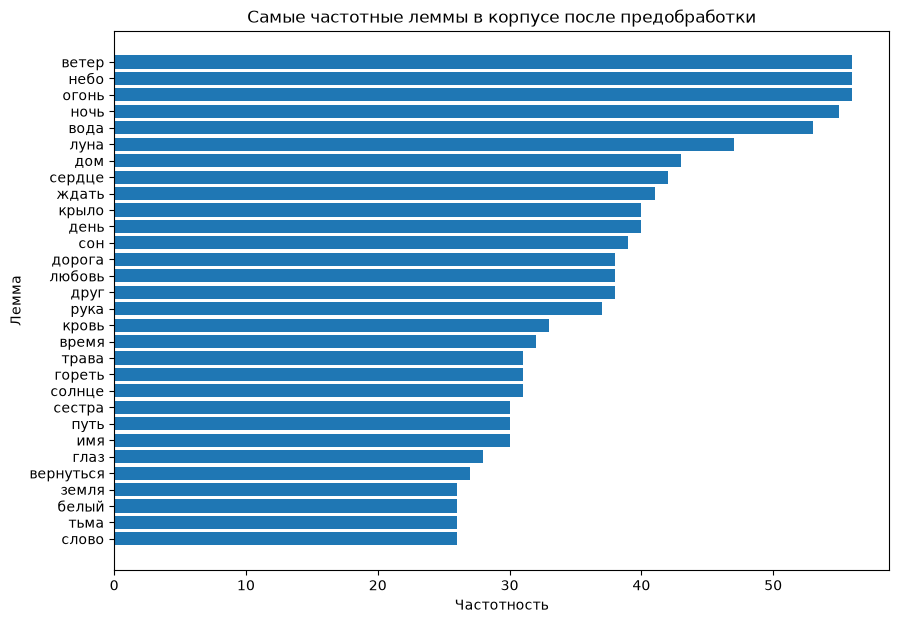

In [16]:
plt.figure(figsize=(10, 7))

plt.barh(
    freq_df["lemma"][::-1],
    freq_df["frequency"][::-1]
)

plt.xlabel("Частотность")
plt.ylabel("Лемма")
plt.title("Самые частотные леммы в корпусе после предобработки")

plt.show()

Для анализа удобнее использовать не список, а строку, поэтому создадим две дополнительные колонки. Основным вариантом для дальнейшего анализа будет `text_no_repeats_for_model`.

In [17]:
# Превращаем списки лемм обратно в строки.

songs["text_with_repeats_for_model"] = songs["lemmas_with_repeats"].apply(" ".join)
songs["text_no_repeats_for_model"] = songs["lemmas_no_repeats"].apply(" ".join)

songs[[
    "album_year",
    "album_title",
    "song_title",
    "text_no_repeats_for_model"
]].head()

,album_year,album_title,song_title,text_no_repeats_for_model
0,2003,Дорога сна,Дорога сна,налить вино венценосный брат восходить полный ...
1,2003,Дорога сна,Горец,горец парень удалой широкоплечий высокий сильн...
2,2003,Дорога сна,Ольга,эльга эльга звучать поле ломать друг друг крес...
3,2003,Дорога сна,Лорд Грегори,полночный час угрюмый тихнуть гром греметь пор...
4,2003,Дорога сна,Змей,иначе былой год колдовать земля небо див дивны...


### Сохранение обработанного корпуса

После предобработки сохраним датафрейм в отдельный файл, чтобы дальше работать уже с готовым корпусом и не повторять чтение файлов, удаление повторов и лемматизацию при каждом запуске тетрадки.

In [18]:
songs.to_pickle("melnitsa_preprocessed.pkl")

## Первичный анализ корпуса

После предобработки можно перейти к описанию корпуса. На этом этапе мы посмотрим, как устроены данные до тематического моделирования: сколько песен вошло в каждый альбом, насколько различаются тексты по длине и есть ли заметные различия между альбомами.

In [19]:
album_length_stats = (
    songs
    .groupby(["album_year", "album_title"])
    .agg(
        songs_count=("song_id", "count"),
        mean_lemmas=("n_lemmas_no_repeats", "mean"),
        min_lemmas=("n_lemmas_no_repeats", "min"),
        max_lemmas=("n_lemmas_no_repeats", "max")
    )
    .reset_index()
)

album_length_stats[["mean_lemmas"]] = album_length_stats[["mean_lemmas"]].round(1)

album_length_stats

,album_year,album_title,songs_count,mean_lemmas,min_lemmas,max_lemmas
0,2003,Дорога сна,10,84.7,41,119
1,2005,Перевал,9,103.9,43,199
2,2006,Зов Крови,14,70.2,28,107
3,2009,Дикие травы,12,89.5,38,148
4,2012,Ангелофрения,11,90.4,59,188
5,2015,Алхимия,12,83.6,54,119
6,2016,Химера,11,85.9,42,111
7,2021,Манускрипт,10,77.5,39,104
8,2023,Символ солнца,11,78.5,53,114


По средней длине песен альбомы различаются, но без экстремальных перекосов. Самым длинным по средней длине оказывается **«Перевал»** — около 104 лемм, а самым коротким — **«Зов Крови»** — около 70 лемм.

Тематическое моделирование будет работать с текстами разной длины, но различия не настолько велики, чтобы исключать какие-то альбомы из корпуса.

## TF-IDF

Перед тематическим моделированием посмотрим, какие леммы наиболее характерны для каждого альбома. Для этого используем TF-IDF: он повышает вес слов, которые часто встречаются в одном альбоме, но не являются одинаково частотными во всём корпусе.

Здесь каждый альбом рассматривается как один объединённый документ, составленный из всех его песен.

In [21]:
# Объединяем песни каждого альбома в один текст
album_texts = (
    songs
    .groupby(["album_year", "album_title"])["text_no_repeats_for_model"]
    .apply(lambda texts: " ".join(texts))
    .reset_index()
)

# Строим TF-IDF-матрицу
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(album_texts["text_no_repeats_for_model"])

feature_names = tfidf.get_feature_names_out()

# Для каждого альбома достаём 10 слов с самым высоким TF-IDF
top_words_by_album = []

for album_index, row in album_texts.iterrows():
    scores = tfidf_matrix[album_index].toarray()[0]
    top_indices = scores.argsort()[::-1][:10]
    top_words = [feature_names[i] for i in top_indices]

    top_words_by_album.append({
        "album_year": row["album_year"],
        "album_title": row["album_title"],
        "top_tfidf_words": ", ".join(top_words)
    })

top_words_by_album = pd.DataFrame(top_words_by_album)

top_words_by_album

,album_year,album_title,top_tfidf_words
0,2003,Дорога сна,"конь, вернуть, ольга, домой, вернуться, горец,..."
1,2005,Перевал,"королевна, гора, кобыла, платить, скоро, весна..."
2,2006,Зов Крови,"сестра, взять, дьявол, вода, волна, думать, ве..."
3,2009,Дикие травы,"ведьма, танцевать, олень, ветер, семь, жена, к..."
4,2012,Ангелофрения,"москва, контрабанда, больной, фивы, река, лебе..."
5,2015,Алхимия,"огонь, воздух, стекло, поезд, друг, лёд, кит, ..."
6,2016,Химера,"бесполезно, игла, луна, катиться, вода, любовь..."
7,2021,Манускрипт,"нужный, джинн, вновь, лоза, очень, грифон, гор..."
8,2023,Символ солнца,"дом, огонь, ястреб, бежать, тьма, ребёнок, пои..."


TF-IDF-таблица показывает слова, которые наиболее характерны для отдельных альбомов по сравнению с остальным корпусом. В списке есть как легко интерпретируемые образы, так и более общие слова. В песенных текстах даже относительно общая лексика может быть тематически значимой. Например, слова, связанные с возвращением, домом, временем или движением, могут отражать устойчивые мотивы творчества исполнителя. По этой причине они не удаляются из корпуса.

## Тематическое моделирование

Теперь перейдём к тематическому моделированию. В качестве первого варианта используем NMF-модель на TF-IDF-матрице.

В отличие от простой частотности, тематическая модель пытается выделить группы слов, которые часто встречаются вместе в одних и тех же песнях. Каждая песня будет представлена как сочетание нескольких тем, а каждая тема — как набор наиболее характерных слов. Возьмём 7 тем (ранее была посчитана когерентность).

In [28]:
# Строим TF-IDF-матрицу по песням
topic_vectorizer = TfidfVectorizer(
    min_df=2,
    max_df=0.8
)

X = topic_vectorizer.fit_transform(songs["text_no_repeats_for_model"])

feature_names = topic_vectorizer.get_feature_names_out()


# Обучаем NMF-модель
n_topics = 7
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

song_topic_matrix = nmf_model.fit_transform(X)


# Смотрим самые важные слова в каждой теме
topics = []

for topic_id, topic_weights in enumerate(nmf_model.components_):
    top_indices = topic_weights.argsort()[::-1][:12]
    top_words = [feature_names[i] for i in top_indices]

    topics.append({
        "topic": topic_id + 1,
        "top_words": ", ".join(top_words)
    })

topics_df = pd.DataFrame(topics)

topics_df

,topic,top_words
0,1,"друг, сон, остаться, любовь, имя, дорога, вете..."
1,2,"дом, тысяча, дверь, луна, смерть, умереть, шур..."
2,3,"нужный, зима, лоза, снег, брат, домой, нужно, ..."
3,4,"вода, думать, ждать, волна, река, небо, ветер,..."
4,5,"гореть, чёрный, ночь, игла, золото, огонь, ден..."
5,6,"сестра, народ, честной, костёр, коса, вслед, т..."
6,7,"бежать, колесо, луна, катиться, лес, гость, ве..."


Полученные темы можно предварительно интерпретировать. Некоторые выглядят достаточно цельно. Например, тема 4 связана с водой, рекой, волной и ожиданием; тема 5 — с огнём, ночью, золотом и темнотой; тема 7 — с движением, лесом, гостем и луной. При этом часть тем остаётся смешанной, что нормально для небольшого корпуса песен: один текст может сочетать несколько мотивов, а границы между темами не всегда будут чёткими.

Дальше нужно посмотреть на то, какие темы сильнее представлены в разных песнях и альбомах.

In [24]:
# Для каждой песни находим тему с самым большим весом

songs["main_topic"] = song_topic_matrix.argmax(axis=1) + 1
songs["main_topic_weight"] = song_topic_matrix.max(axis=1)

songs[[
    "album_year",
    "album_title",
    "song_title",
    "main_topic",
    "main_topic_weight"
]].head(20)

,album_year,album_title,song_title,main_topic,main_topic_weight
0,2003,Дорога сна,Дорога сна,1,0.222105
1,2003,Дорога сна,Горец,2,0.096518
2,2003,Дорога сна,Ольга,1,0.177563
3,2003,Дорога сна,Лорд Грегори,7,0.195410
4,2003,Дорога сна,Змей,5,0.141750
5,2003,Дорога сна,Зима,4,0.243094
6,2003,Дорога сна,Оборотень,7,0.196480
7,2003,Дорога сна,Воин вереска,4,0.290573
8,2003,Дорога сна,Мора,5,0.127516
9,2003,Дорога сна,На Север,4,0.306053


### Тематические профили альбомов

После обучения модели каждая песня представлена как набор весов по темам. Для каждого альбома посчитаем средний вес каждой темы. Так мы получим тематический профиль альбома — то есть увидим, какие темы сильнее представлены в разных альбомах.

In [29]:
# Добавляем веса тем в таблицу с песнями
for topic_id in range(n_topics):
    songs[f"topic_{topic_id + 1}"] = song_topic_matrix[:, topic_id]


# Считаем средний вес каждой темы внутри каждого альбома
topic_columns = [f"topic_{i + 1}" for i in range(n_topics)]

album_topic_profiles = (
    songs
    .groupby(["album_year", "album_title"])[topic_columns]
    .mean()
    .reset_index()
)

album_topic_profiles

,album_year,album_title,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7
0,2003,Дорога сна,0.060054,0.016379,0.018648,0.119224,0.027076,0.020772,0.055983
1,2005,Перевал,0.045539,0.024720,0.011622,0.127950,0.091075,0.023707,0.074331
2,2006,Зов Крови,0.017670,0.025103,0.004377,0.158535,0.026553,0.106541,0.057172
3,2009,Дикие травы,0.041618,0.045142,0.040432,0.088161,0.080304,0.037249,0.023286
4,2012,Ангелофрения,0.074811,0.058402,0.017439,0.062497,0.069511,0.013481,0.019535
5,2015,Алхимия,0.127028,0.019365,0.015995,0.011632,0.061448,0.024745,0.038109
6,2016,Химера,0.053014,0.031589,0.016780,0.087447,0.090117,0.018089,0.086336
7,2021,Манускрипт,0.042820,0.024636,0.195048,0.028314,0.063777,0.088119,0.000000
8,2023,Символ солнца,0.013197,0.114867,0.034712,0.036397,0.106519,0.048869,0.050809


В ранних альбомах **«Дорога сна»**, **«Перевал»** и особенно в **«Зов Крови»** заметно выделяется тема 4. В альбоме **«Зов Крови»** также сильнее выражена тема 6. Для **«Алхимии»** наиболее заметна тема 1, для **«Манускрипта»** — тема 3, а для **«Символа солнца»** — темы 2 и 5.

### Визуализация тематических профилей альбомов

Чтобы легче сравнить альбомы между собой, визуализируем средние веса тем в виде тепловой карты.

Строки соответствуют альбомам, столбцы — темам, а цвет показывает, насколько сильно тема выражена в конкретном альбоме. Такая визуализация позволяет увидеть, есть ли у альбомов разные тематические профили и просматриваются ли изменения по хронологии.

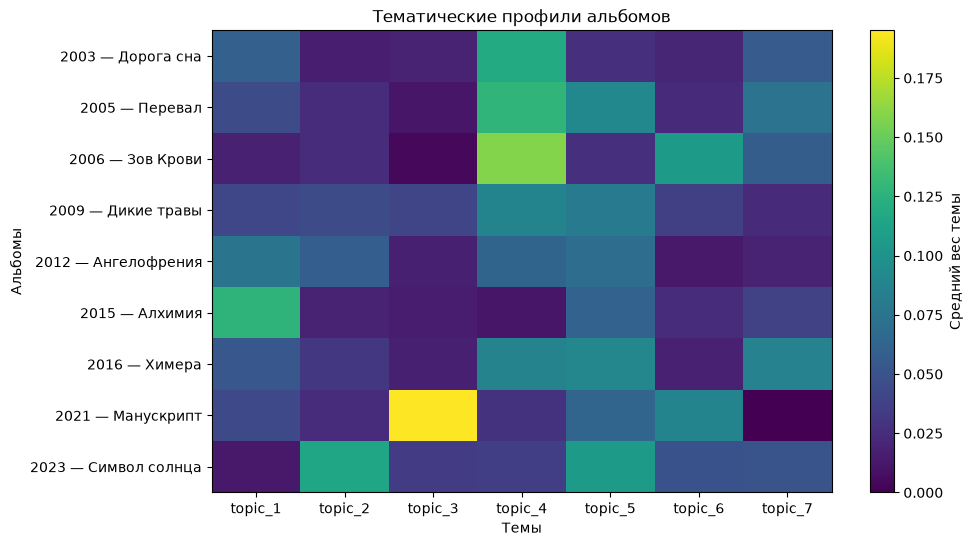

In [30]:
heatmap_data = album_topic_profiles.copy()

heatmap_data["album_label"] = (
    heatmap_data["album_year"].astype(str) 
    + " — " 
    + heatmap_data["album_title"]
)

heatmap_data = heatmap_data.set_index("album_label")[topic_columns]


plt.figure(figsize=(10, 6))
plt.imshow(heatmap_data, aspect="auto")

plt.xticks(
    ticks=range(len(topic_columns)),
    labels=topic_columns
)

plt.yticks(
    ticks=range(len(heatmap_data.index)),
    labels=heatmap_data.index
)

plt.colorbar(label="Средний вес темы")

plt.title("Тематические профили альбомов")
plt.xlabel("Темы")
plt.ylabel("Альбомы")

plt.show()

Тепловая карта показывает, что темы распределены по альбомам неравномерно. Наиболее заметные различия видны в нескольких случаях, описанных выше. Также видно, что тематическая структура не полностью совпадает с хронологией: соседние по времени альбомы не всегда имеют похожие профили. Однако некоторые локальные сходства всё же есть, например между ранними альбомами по теме 4 и между альбомами 2009–2015 по теме 5.

Эта визуализация поддерживает первую гипотезу исследования: альбомы могут обладать собственными тематическими профилями. Но для более строгой проверки дальше нужно сравнить тематическую близость песен внутри одного альбома и между разными альбомами.

### Проверка тематической близости песен внутри альбомов

Теперь проверим, действительно ли песни одного альбома ближе друг к другу в тематическом пространстве. Для этого используем матрицу `song_topic_matrix`, где каждая песня представлена набором весов по темам. Затем считаем косинусное расстояние между всеми парами песен и сравниваем два случая: пары песен из одного альбома и пары песен из разных альбомов.

Если среднее расстояние внутри альбомов меньше, чем между альбомами, это будет поддерживать гипотезу об альбомной тематической связности.

In [32]:
# Считаем косинусные расстояния между всеми песнями по их тематическим векторам

distance_matrix = pairwise_distances(song_topic_matrix, metric="cosine")

pair_distances = []

for i in range(len(songs)):
    for j in range(i + 1, len(songs)):
        pair_distances.append({
            "song_1": songs.iloc[i]["song_title"],
            "song_2": songs.iloc[j]["song_title"],
            "album_1": songs.iloc[i]["album_title"],
            "album_2": songs.iloc[j]["album_title"],
            "same_album": songs.iloc[i]["album_id"] == songs.iloc[j]["album_id"],
            "distance": distance_matrix[i, j]
        })

pair_distances = pd.DataFrame(pair_distances)

distance_summary = (
    pair_distances
    .groupby("same_album")
    .agg(
        pairs_count=("distance", "count"),
        mean_distance=("distance", "mean"),
        median_distance=("distance", "median")
    )
    .reset_index()
)

distance_summary

,same_album,pairs_count,mean_distance,median_distance
0,False,4436,0.678074,0.765029
1,True,514,0.621662,0.697963


Среднее косинусное расстояние между песнями одного альбома составляет около **0,62**, а между песнями разных альбомов — около **0,68**. Медианное расстояние также ниже для песен внутри одного альбома.

Вывод: песни из одного альбома в среднем ближе друг к другу по тематическим векторам, чем песни из разных альбомов. Однако разница не очень большая, поэтому этот результат нужно проверить статистически.

### Статистическая проверка: permutation test

Предыдущее сравнение показало, что песни одного альбома в среднем тематически ближе друг к другу, чем песни из разных альбомов. Однако нужно проверить, могла ли такая разница возникнуть случайно.

Для этого используем permutation test:
1. считаем реальную разницу между средним расстоянием внутри альбомов и между альбомами;
2. случайно перемешиваем альбомные метки между песнями;
3. снова считаем такую же разницу;
4. повторяем это много раз;
5. проверяем, насколько часто случайная разница оказывается не меньше реальной.

Если такое происходит редко, значит альбомная связность действительно выражена сильнее, чем при случайном распределении песен по альбомам.

In [33]:
real_within = pair_distances[pair_distances["same_album"]]["distance"].mean()
real_between = pair_distances[~pair_distances["same_album"]]["distance"].mean()

real_difference = real_between - real_within

real_difference

np.float64(0.05641149464594819)

In [34]:
n_permutations = 1000
random_differences = []

album_ids = songs["album_id"].values

for _ in range(n_permutations):
    shuffled_album_ids = np.random.permutation(album_ids)

    random_pair_distances = []

    for i in range(len(songs)):
        for j in range(i + 1, len(songs)):
            same_album_random = shuffled_album_ids[i] == shuffled_album_ids[j]
            random_pair_distances.append({
                "same_album": same_album_random,
                "distance": distance_matrix[i, j]
            })

    random_pair_distances = pd.DataFrame(random_pair_distances)

    random_within = random_pair_distances[random_pair_distances["same_album"]]["distance"].mean()
    random_between = random_pair_distances[~random_pair_distances["same_album"]]["distance"].mean()

    random_differences.append(random_between - random_within)

random_differences = np.array(random_differences)

p_value = (random_differences >= real_difference).mean()

p_value

np.float64(0.0)

Permutation test показал, что при 1000 случайных перемешиваниях альбомных меток ни разу не получилась разница, равная или превышающая реальную. Поэтому значение `p-value` в эксперименте равно 0.0, то есть `p < 0.001`.

Это подтверждает вывод о том, что альбомная тематическая связность не является случайной: песни одного альбома действительно оказываются тематически ближе друг к другу, чем песни из разных альбомов.

### Визуализация permutation test

Чтобы наглядно показать результат статистической проверки, построим распределение случайных разниц, полученных при перемешивании альбомных меток.

Вертикальная линия показывает реальную разницу между межальбомными и внутриальбомными расстояниями. Если она находится далеко справа от случайного распределения, значит реальная альбомная связность выражена сильнее, чем можно было бы ожидать случайно.

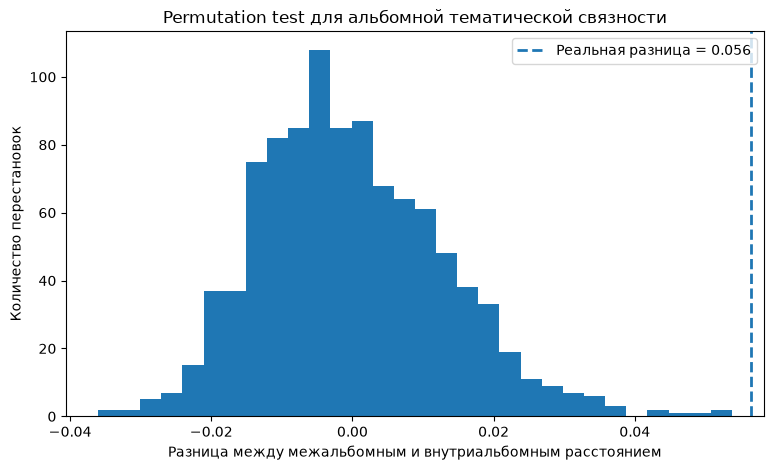

In [35]:
plt.figure(figsize=(9, 5))

plt.hist(random_differences, bins=30)

plt.axvline(
    real_difference,
    linestyle="--",
    linewidth=2,
    label=f"Реальная разница = {real_difference:.3f}"
)

plt.xlabel("Разница между межальбомным и внутриальбомным расстоянием")
plt.ylabel("Количество перестановок")
plt.title("Permutation test для альбомной тематической связности")
plt.legend()

plt.show()

На графике видно, что реальная разница между межальбомными и внутриальбомными расстояниями находится далеко правее распределения случайных перестановок. Это означает, что в реальном корпусе песни одного альбома тематически ближе друг к другу сильнее, чем можно было бы ожидать при случайном распределении песен по альбомам.

Таким образом, первая гипотеза подтверждается: альбомы обладают тематической связностью. При этом важно учитывать, что речь идёт не о полной изолированности альбомов друг от друга, а о статистически выраженной тенденции.

### Проверка хронологической гипотезы

Теперь проверим вторую гипотезу: альбомы, вышедшие ближе друг к другу по времени, могут быть тематически ближе.

Для этого перейдём от уровня песен к уровню альбомов. У каждого альбома уже есть тематический профиль — средний вес каждой темы по всем песням альбома. Теперь можно сравнить альбомы попарно:
- посчитать тематическое расстояние между профилями двух альбомов;
- посчитать разницу между годами выхода этих альбомов;
- проверить, связаны ли тематическая дистанция и хронологическая дистанция.

Если хронологическая гипотеза верна, то альбомы с небольшой разницей в годах должны иметь меньшую тематическую дистанцию.

In [36]:
# Считаем расстояния между тематическими профилями альбомов

album_vectors = album_topic_profiles[topic_columns].values
album_distances = pairwise_distances(album_vectors, metric="cosine")

album_pairs = []

for i in range(len(album_topic_profiles)):
    for j in range(i + 1, len(album_topic_profiles)):
        album_1 = album_topic_profiles.iloc[i]
        album_2 = album_topic_profiles.iloc[j]

        album_pairs.append({
            "album_1": album_1["album_title"],
            "year_1": album_1["album_year"],
            "album_2": album_2["album_title"],
            "year_2": album_2["album_year"],
            "year_distance": abs(album_1["album_year"] - album_2["album_year"]),
            "topic_distance": album_distances[i, j]
        })

album_pairs = pd.DataFrame(album_pairs)

album_pairs.sort_values("topic_distance").head(10)

,album_1,year_1,album_2,year_2,year_distance,topic_distance
12,Перевал,2005,Химера,2016,11,0.027222
0,Дорога сна,2003,Перевал,2005,2,0.068666
21,Дикие травы,2009,Ангелофрения,2012,3,0.076196
9,Перевал,2005,Дикие травы,2009,4,0.082241
23,Дикие травы,2009,Химера,2016,7,0.101083
5,Дорога сна,2003,Химера,2016,13,0.118832
27,Ангелофрения,2012,Химера,2016,4,0.128650
1,Дорога сна,2003,Зов Крови,2006,3,0.133583
2,Дорога сна,2003,Дикие травы,2009,6,0.152790
10,Перевал,2005,Ангелофрения,2012,7,0.153837


Посмотрим, связана ли тематическая дистанция между альбомами с хронологической дистанцией. Для этого посчитаем корреляцию между двумя величинами. Если корреляция положительная, это будет означать, что более далёкие по времени альбомы в среднем тематически менее похожи.

In [37]:
pearson_corr = album_pairs["year_distance"].corr(
    album_pairs["topic_distance"],
    method="pearson"
)

spearman_corr = album_pairs["year_distance"].corr(
    album_pairs["topic_distance"],
    method="spearman"
)

print("Корреляция Пирсона:", round(pearson_corr, 3))
print("Корреляция Спирмена:", round(spearman_corr, 3))

Корреляция Пирсона: 0.421
Корреляция Спирмена: 0.393


Корреляция положительная: более далёкие по времени альбомы в среднем действительно оказываются более далёкими тематически. Однако связь умеренная. Иными словами, альбомы не выстраиваются в идеально линейную эволюцию, но временной фактор всё же заметен.

### Визуализация связи между хронологией и тематической дистанцией

Чтобы наглядно проверить хронологическую гипотезу, построим график рассеяния. Каждая точка — это пара альбомов.

По оси X отложена разница между годами выхода двух альбомов, по оси Y — тематическое расстояние между ними. Если точки в целом поднимаются вверх слева направо, это означает, что более далёкие по времени альбомы чаще оказываются более далёкими тематически.

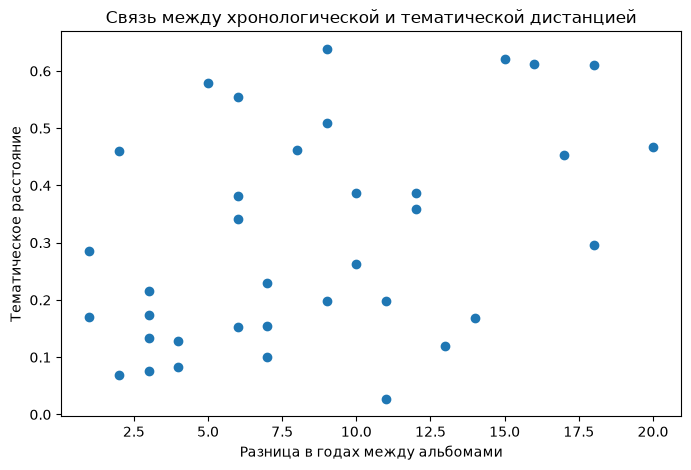

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(
    album_pairs["year_distance"],
    album_pairs["topic_distance"]
)

plt.xlabel("Разница в годах между альбомами")
plt.ylabel("Тематическое расстояние")
plt.title("Связь между хронологической и тематической дистанцией")

plt.show()

Точки расположены не по прямой линии, а с большим разбросом. Некоторые альбомы, далёкие по времени, могут сохранять общие мотивы, а некоторые относительно близкие по времени — заметно различаться тематически. Вторая гипотеза подтверждается частично: временная дистанция связана с тематической, но не является единственным фактором.

### Матрица тематической дистанции между альбомами

Теперь посмотрим на тематическую близость альбомов не через общий график, а попарно. Матрица показывает расстояние между каждым альбомом и всеми остальными.

Чем меньше значение, тем ближе альбомы по тематическому профилю. Такая визуализация помогает увидеть, какие альбомы образуют локальные группы и совпадает ли это с хронологией.

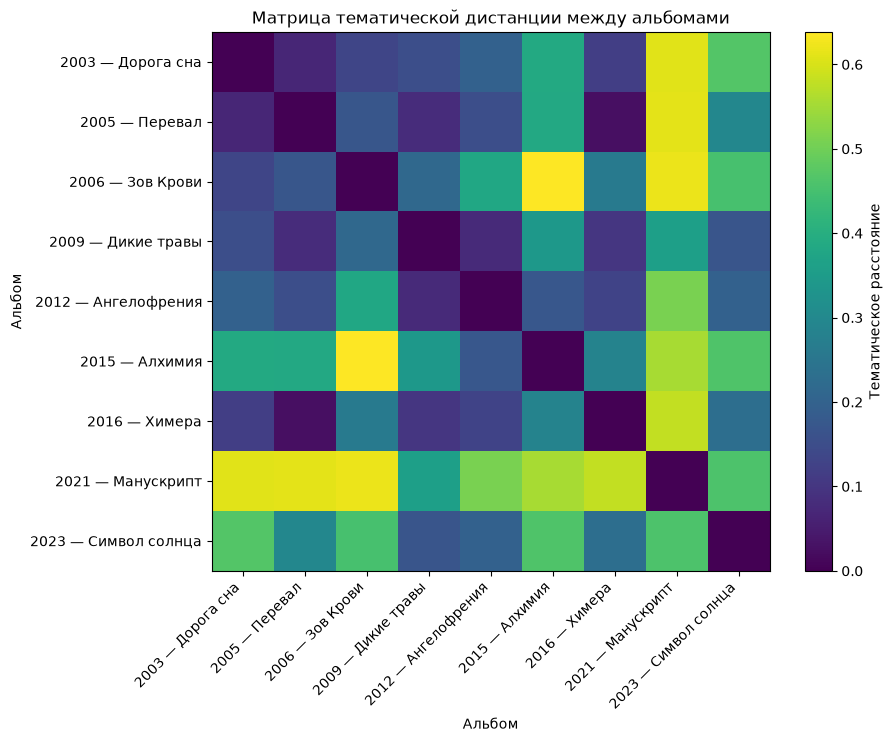

In [40]:
album_labels = (
    album_topic_profiles["album_year"].astype(str)
    + " — "
    + album_topic_profiles["album_title"]
)

plt.figure(figsize=(9, 7))

plt.imshow(album_distances, aspect="auto")

plt.xticks(
    ticks=range(len(album_labels)),
    labels=album_labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=range(len(album_labels)),
    labels=album_labels
)

plt.colorbar(label="Тематическое расстояние")

plt.title("Матрица тематической дистанции между альбомами")
plt.xlabel("Альбом")
plt.ylabel("Альбом")

plt.show()

In [41]:
# Самые близкие пары альбомов по тематическому расстоянию

album_pairs.sort_values("topic_distance").head(10)

,album_1,year_1,album_2,year_2,year_distance,topic_distance
12,Перевал,2005,Химера,2016,11,0.027222
0,Дорога сна,2003,Перевал,2005,2,0.068666
21,Дикие травы,2009,Ангелофрения,2012,3,0.076196
9,Перевал,2005,Дикие травы,2009,4,0.082241
23,Дикие травы,2009,Химера,2016,7,0.101083
5,Дорога сна,2003,Химера,2016,13,0.118832
27,Ангелофрения,2012,Химера,2016,4,0.128650
1,Дорога сна,2003,Зов Крови,2006,3,0.133583
2,Дорога сна,2003,Дикие травы,2009,6,0.152790
10,Перевал,2005,Ангелофрения,2012,7,0.153837


Список ближайших пар показывает, что тематическая близость альбомов не сводится только к хронологии.

С одной стороны, среди близких пар есть соседние или близкие по времени альбомы: **«Дорога сна» — «Перевал»**, **«Дикие травы» — «Ангелофрения»**, **«Дорога сна» — «Зов Крови»**. Это поддерживает хронологическую гипотезу.

С другой стороны, самая близкая пара — **«Перевал» — «Химера»**, хотя между ними 11 лет. Также близкими оказываются **«Дорога сна» — «Химера»** и **«Дикие травы» — «Химера»**. Это показывает, что в корпусе есть устойчивые мотивы, которые могут возвращаться через большие промежутки времени.

Поэтому хронологическая гипотеза подтверждается только частично: время влияет на тематическую близость, но отдельные альбомы могут быть связаны не по хронологии, а по повторяющимся образам и мотивам.

### Кластеризация альбомов

После попарного сравнения альбомов можно посмотреть, какие альбомы образуют группы по тематическим профилям. Для этого используем иерархическую кластеризацию.

В этой визуализации близкие по тематическому профилю альбомы соединяются раньше, а более далёкие — позже. Это позволяет увидеть, совпадают ли тематические группы с хронологией или альбомы объединяются по другим признакам.

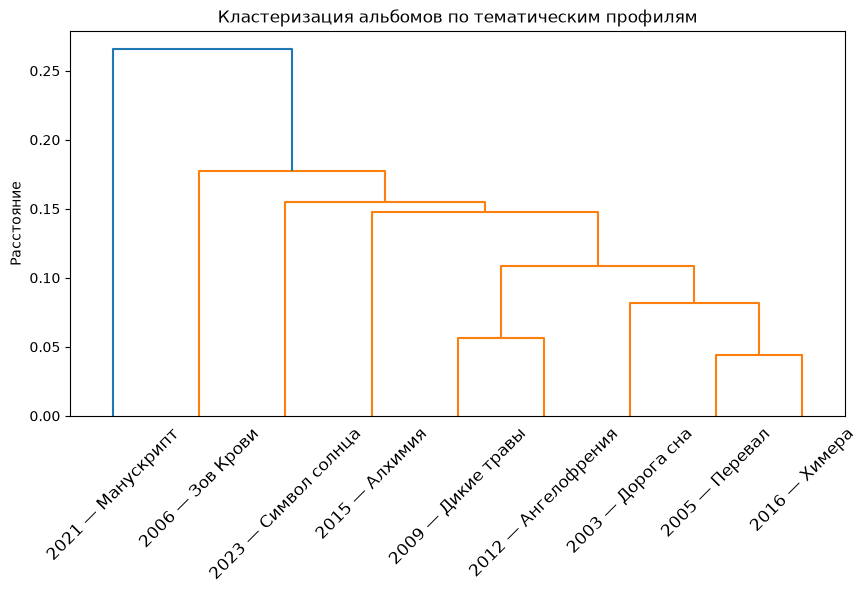

In [43]:
# Иерархическая кластеризация альбомов по тематическим профилям

album_labels = (
    album_topic_profiles["album_year"].astype(str)
    + " — "
    + album_topic_profiles["album_title"]
)

album_vectors = album_topic_profiles[topic_columns].values

linked_albums = linkage(
    album_vectors,
    method="ward"
)

plt.figure(figsize=(10, 5))

dendrogram(
    linked_albums,
    labels=album_labels.tolist(),
    leaf_rotation=45
)

plt.title("Кластеризация альбомов по тематическим профилям")
plt.ylabel("Расстояние")
plt.show()

Дендрограмма показывает, что тематическая группировка альбомов скорее не совпадает с хронологией. Ближе всего объединяются **«Перевал»** и **«Химера»**, хотя между ними большой временной разрыв. К ним близко примыкает **«Дорога сна»**, то есть часть ранней образности оказывается связанной с более поздним альбомом.

Отдельно группируются **«Дикие травы»** и **«Ангелофрения»**, что согласуется с их относительно близким положением во времени. **«Алхимия»**, **«Символ солнца»** и **«Зов Крови»** присоединяются к общей структуре дальше, а **«Манускрипт»** оказывается наиболее обособленным.

## Сравнение корпуса с повторами и без повторов

До этого основной анализ строился на версии корпуса без повторяющихся строк. Это решение связано с особенностями песенного текста: припевы и рефрены могут искусственно усиливать отдельные слова и влиять на тематическую модель.

Однако полное удаление повторов тоже является исследовательским решением, которое может повлиять на результат. Поэтому дополнительно сравним две версии корпуса. Задача этого сравнения — проверить, сохраняются ли основные выводы при изменении способа подготовки текста. Если результаты похожи, это будет означать, что выводы не зависят полностью от удаления припевов и повторяющихся строк.

In [44]:
# Строим тематическую модель для корпуса с повторами строк
vectorizer_repeats = TfidfVectorizer(
    min_df=2,
    max_df=0.8
)

X_repeats = vectorizer_repeats.fit_transform(
    songs["text_with_repeats_for_model"]
)

nmf_model_repeats = NMF(
    n_components=n_topics,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

song_topic_matrix_repeats = nmf_model_repeats.fit_transform(X_repeats)


# Считаем расстояния между песнями
distance_matrix_repeats = pairwise_distances(
    song_topic_matrix_repeats,
    metric="cosine"
)

pair_distances_repeats = []

for i in range(len(songs)):
    for j in range(i + 1, len(songs)):
        pair_distances_repeats.append({
            "same_album": songs.iloc[i]["album_id"] == songs.iloc[j]["album_id"],
            "distance": distance_matrix_repeats[i, j]
        })

pair_distances_repeats = pd.DataFrame(pair_distances_repeats)

repeats_within = pair_distances_repeats[
    pair_distances_repeats["same_album"]
]["distance"].mean()

repeats_between = pair_distances_repeats[
    ~pair_distances_repeats["same_album"]
]["distance"].mean()

repeats_difference = repeats_between - repeats_within


# Считаем тематические профили альбомов для корпуса с повторами
songs_repeats_topics = songs[[
    "album_year",
    "album_title"
]].copy()

for topic_id in range(n_topics):
    songs_repeats_topics[f"topic_{topic_id + 1}"] = song_topic_matrix_repeats[:, topic_id]

album_topic_profiles_repeats = (
    songs_repeats_topics
    .groupby(["album_year", "album_title"])[topic_columns]
    .mean()
    .reset_index()
)


# Считаем связь хронологической и тематической дистанции
album_vectors_repeats = album_topic_profiles_repeats[topic_columns].values

album_distances_repeats = pairwise_distances(
    album_vectors_repeats,
    metric="cosine"
)

album_pairs_repeats = []

for i in range(len(album_topic_profiles_repeats)):
    for j in range(i + 1, len(album_topic_profiles_repeats)):
        album_1 = album_topic_profiles_repeats.iloc[i]
        album_2 = album_topic_profiles_repeats.iloc[j]

        album_pairs_repeats.append({
            "year_distance": abs(album_1["album_year"] - album_2["album_year"]),
            "topic_distance": album_distances_repeats[i, j]
        })

album_pairs_repeats = pd.DataFrame(album_pairs_repeats)

repeats_pearson = album_pairs_repeats["year_distance"].corr(
    album_pairs_repeats["topic_distance"],
    method="pearson"
)

repeats_spearman = album_pairs_repeats["year_distance"].corr(
    album_pairs_repeats["topic_distance"],
    method="spearman"
)


# Сравниваем с уже посчитанными результатами для корпуса без повторов
corpus_comparison = pd.DataFrame([
    {
        "corpus": "Без повторов",
        "within_album_distance": real_within,
        "between_album_distance": real_between,
        "difference": real_difference,
        "pearson_year_topic": pearson_corr,
        "spearman_year_topic": spearman_corr
    },
    {
        "corpus": "С повторами",
        "within_album_distance": repeats_within,
        "between_album_distance": repeats_between,
        "difference": repeats_difference,
        "pearson_year_topic": repeats_pearson,
        "spearman_year_topic": repeats_spearman
    }
])

corpus_comparison.round(3)

,corpus,within_album_distance,between_album_distance,difference,pearson_year_topic,spearman_year_topic
0,Без повторов,0.622,0.678,0.056,0.421,0.393
1,С повторами,0.617,0.686,0.068,0.448,0.428


Сравнение двух версий корпуса показывает, что основные результаты сохраняются как для текстов без повторов, так и для полных текстов с повторами.

В обоих случаях песни одного альбома оказываются тематически ближе друг к другу, чем песни разных альбомов. Более того, в корпусе с повторами разница между внутриальбомным и межальбомным расстоянием даже немного выше: 0,068 против 0,056. Это означает, что удаление повторяющихся строк не создаёт эффект альбомной связности искусственно.

Хронологическая гипотеза также сохраняется в обеих версиях корпуса: корреляция между разницей в годах и тематической дистанцией остаётся положительной. В корпусе с повторами она немного выше, но различие не меняет общего вывода.

Таким образом, корпус без повторов можно оставить основным вариантом анализа, потому что он снижает влияние припевов и рефренов. При этом сравнение с корпусом с повторами показывает, что главные результаты устойчивы.

# Выводы

В проекте был проанализирован корпус из 100 песен группы «Мельница», распределённых по 9 альбомам 2003–2023 годов. Основной задачей было проверить, обладают ли альбомы собственными тематическими профилями и связана ли тематическая близость альбомов с хронологией их выхода.

На этапе предобработки были созданы две версии корпуса: с повторами строк и без повторяющихся строк. Основной анализ сделан без повторов, но результаты проверены на корпусе с повторами и оказались устойчивыми. Проверка длины текстов показала, что после удаления повторов корпус остаётся пригодным для анализа: даже самые короткие песни не пришлось исключать.

Тематическое моделирование было выполнено с помощью NMF-модели на TF-IDF-представлении песен. Модель выделила несколько тематических групп, связанных с мотивами дороги, сна, воды, огня, зимы, смерти, движения, леса и мифологических образов. После этого для каждого альбома был построен тематический профиль — среднее распределение тем по песням альбома.

Первая гипотеза подтвердилась: песни одного альбома в среднем тематически ближе друг к другу, чем песни из разных альбомов. Среднее косинусное расстояние между песнями одного альбома составило около 0,62, а между песнями разных альбомов — около 0,68. Permutation test показал, что такая разница не возникает случайно: при 1000 случайных перемешиваниях альбомных меток ни разу не была получена разница, равная или превышающая реальную. Это позволяет говорить о наличии альбомной тематической связности.

Вторая гипотеза подтвердилась частично. Корреляция между хронологической и тематической дистанцией оказалась положительной: коэффициент Пирсона составил 0,421, коэффициент Спирмена — 0,393. Это означает, что более далёкие по времени альбомы в среднем действительно оказываются более далёкими тематически. Однако связь умеренная, а не сильная, поэтому хронология не полностью объясняет тематическую структуру корпуса.

Матрица тематической дистанции и кластеризация альбомов показали, что альбомы группируются не только по времени выхода. Например, близкими оказываются не только соседние по хронологии альбомы, но и альбомы с большим временным разрывом, такие как «Перевал» и «Химера». Это говорит о возвращении устойчивых мотивов и образных комплексов в разные периоды творчества.

Таким образом, альбом можно рассматривать как «слабую» тематическую категорию: песни одного альбома не образуют полностью изолированную группу, но всё же статистически чаще оказываются ближе друг к другу, чем к песням других альбомов. В этом смысле проект развивает логику исследования слабых жанров: проверяется вероятностная связь между формальной группировкой текста и его тематическим профилем.

Ограничения исследования связаны с небольшим размером корпуса, зависимостью результатов от выбранной модели и числа тем, а также с особенностями песенного текста: повторами, припевами, устойчивыми образами и высокой метафоричностью. В дальнейшем можно проверить устойчивость результатов на другом числе тем, сравнить NMF с LDA, добавить второго исполнителя или сопоставить тематические профили с жанровыми и музыкальными характеристиками альбомов.

In [48]:
!jupyter nbconvert --to html "analysis_melnitsa.ipynb" --output index.html

[NbConvertApp] Converting notebook analysis_melnitsa.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 762895 bytes to index.html
